# Картограммы и методы классификации

С классификацией данных мы встречаемся чаще, чем задумываемся об этом. Каждый раз, когда нужно показать на карте интенсивность какого-либо показателя, значения разбивают на несколько групп — **классов** (интервалов), и каждому классу присваивают свой цвет.

От того, как выбраны границы классов, зависит, что увидит читатель карты. Одни и те же данные можно показать так, что территория будет выглядеть однородной, а можно — так, что она окажется резко контрастной.

В этом разделе мы разберём, как строить картограммы: какие показатели для них подходят, как выбрать цветовую палитру и метод классификации. На примере карты плотности населения по муниципальным округам Санкт-Петербурга увидим, насколько сильно этот этап влияет на итоговый результат.


## 0. Импорт библиотек и подготовка данных

### 0.1 Импорт библиотек


In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import mapclassify as mc

import warnings
warnings.filterwarnings("ignore", message="Numba not installed")  # скрываем техническое предупреждение mapclassify

<p style="color:#26528C; font-style:italic"><strong>mapclassify</strong> – библиотека для классификации данных при построении картограмм. Реализует основные методы классификации (равные интервалы, квантили, естественные границы и другие). GeoPandas использует её «под капотом», когда в методе <code>plot()</code> задан параметр <code>scheme</code>.</p>


### 0.2 Подготовка данных

Прочитаем границы муниципальных округов Санкт-Петербурга. В поле `Popul` хранится численность населения.

Для расчёта плотности населения нужна площадь округов, поэтому перепроецируем данные в подходящую зону UTM:


In [2]:
okrug = gpd.read_file("../data/spb_admin.gpkg", layer="okrug")

okrug_utm = okrug.to_crs(okrug.estimate_utm_crs())

Рассчитаем плотность населения — число жителей на 1 км²:


In [3]:
okrug_utm["area_km2"] = okrug_utm.geometry.area / 1_000_000
okrug_utm["pop_density"] = okrug_utm["Popul"] / okrug_utm["area_km2"]

okrug_utm[["NAME", "Popul", "area_km2", "pop_density"]].head()

,NAME,Popul,area_km2,pop_density
0,округ Пискарёвка,61706.0,9.292112,6640.686076
1,Смолячково,742.0,7.933135,93.531751
2,Молодёжное,1685.0,12.386124,136.039328
3,Серово,272.0,9.662041,28.151402
4,Кронштадт,44374.0,20.028559,2215.536304


## 1. Картограмма

**Картограмма** — способ картографического изображения, которым показывают **среднюю интенсивность** явления в пределах территориальных единиц, чаще всего единиц административно-территориального деления (районов, муниципальных округов, регионов). Каждую единицу закрашивают целиком, и чем выше значение показателя, тем насыщеннее цвет или гуще штриховка [Берлянт, 2002; Салищев, 1990]. Типичные примеры: средняя плотность населения, распаханность территории, лесистость.

Основные свойства картограммы:

- **Значение относится ко всей единице целиком.** Картограмма создаёт впечатление, что явление распределено внутри единицы равномерно, хотя на деле это не так. Различия внутри единицы не видны, и чем крупнее единицы, тем сильнее обобщение.
- **Значения группируют в ступени шкалы** (классы, интервалы), и каждой ступени присваивают свой цвет. Реже используют **безынтервальную** (непрерывную) шкалу, в которой каждому значению соответствует свой оттенок (см. раздел 1.3).
- **Картограммы строят по относительным показателям** (раздел 1.1).

```{note}
**Ложный друг переводчика.** В англоязычной литературе картограмме соответствует термин **choropleth map**. Английское слово _cartogram_ означает другое: **анаморфозу**, то есть карту, на которой площади территорий искажены пропорционально значению показателя.
```

### 1.1. Относительные показатели

**Абсолютные значения** (например, численность населения) для картограммы не подходят. Крупная единица почти всегда «выигрывает» просто за счёт своего размера, и карта показывает не интенсивность явления, а размеры округов. Поэтому картограммы строят по **относительным показателям**: плотности (на км²), долям, значениям на 1000 жителей. Именно поэтому выше мы рассчитали плотность населения, а не взяли численность из поля `Popul`.

Абсолютные величины по территориальным единицам показывают другим способом, **картодиаграммой**: в каждой единице размещают диаграммную фигуру (круг, столбик), размер которой пропорционален значению.


### 1.2. Цветовая палитра

Палитру выбирают по типу данных. **Последовательные** палитры (от светлого к тёмному) подходят для количественных значений: плотности, долей, коэффициентов. **Расходящиеся** нужны, когда у данных есть осмысленный центр, например ноль или среднее значение: центральный светлый цвет соответствует ему, а два цвета расходятся в обе стороны. **Качественные** палитры подходят только для категорий без порядка.

![Типы цветовых палитр](./asserts/palettes.png)

Плотность населения — количественный показатель без выделенного центра, поэтому для неё возьмём последовательную палитру `BuPu`. Полный список палитр есть в [документации matplotlib](https://matplotlib.org/stable/users/explain/colors/colormaps.html).


### 1.3. Непрерывная шкала

Построим картограмму плотности населения. По умолчанию метод `plot()` использует **непрерывную шкалу**: каждому значению соответствует свой оттенок.


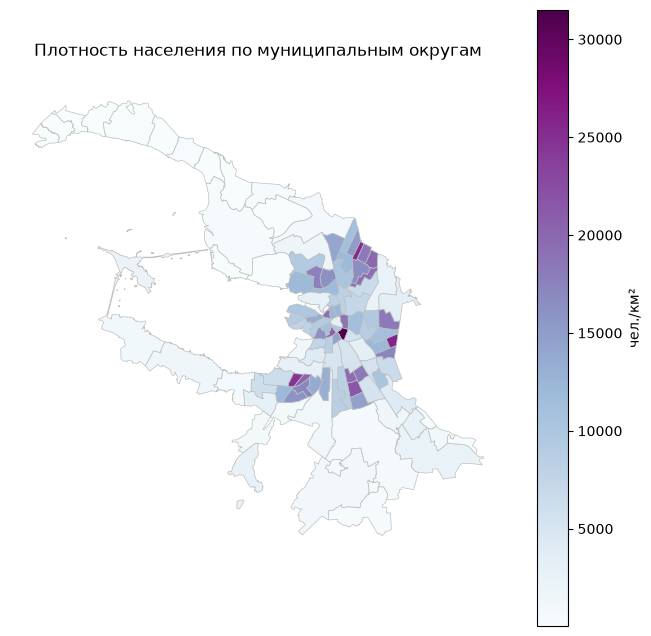

In [4]:
ax = okrug_utm.plot(
    column="pop_density",
    cmap="BuPu",
    linewidth=0.5,
    edgecolor="0.75",
    legend=True,
    legend_kwds={"label": "чел./км²"},
    figsize=(8, 8)
)

ax.set_title("Плотность населения по муниципальным округам")
ax.axis("off")

plt.show()

Непрерывная шкала точно передаёт значения, но читать такую карту трудно: глаз плохо различает близкие оттенки, и сложно понять, к какой группе относится округ. Поэтому на картограммах значения обычно разбивают на небольшое число классов (как правило, от 4 до 7).


## 2. Методы классификации

Методы классификации для картограмм подробно разобраны в учебнике [Slocum et al., 2022]. Методы отличаются тем, по какому принципу проводятся границы классов: по ширине интервалов, по числу объектов в классе, по отклонению от среднего, по разрывам в данных или так, чтобы значения внутри классов были как можно ближе друг к другу.

Универсального метода нет. Чтобы выбрать подходящий, методы сравнивают по нескольким критериям:

- **учитывает ли метод распределение данных**: попадают ли близкие значения в один класс, а далёкие — в разные;
- **легко ли читать легенду**: «круглые» ли границы и понятен ли принцип их построения;
- **равномерно ли используются цвета**: нет ли классов, в которые попало почти всё или почти ничего;
- **можно ли сравнивать несколько карт** с одинаковыми границами классов.

### 2.1. Распределение показателя

Прежде чем классифицировать данные, нужно посмотреть, как они распределены. Гистограмма помогает понять форму распределения, обнаружить выбросы и определить разумное число классов.

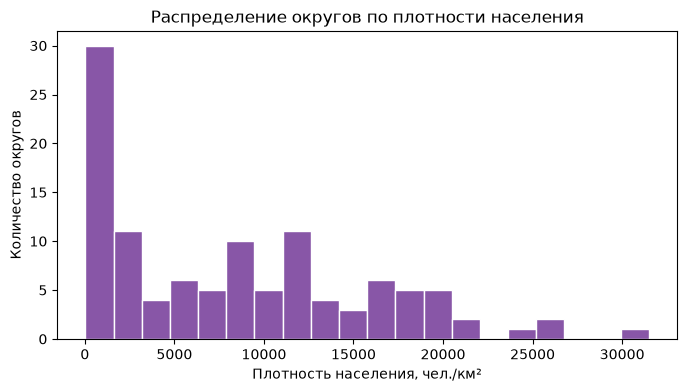

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(okrug_utm["pop_density"], bins=20, color="#8856a7", edgecolor="white")

ax.set_title("Распределение округов по плотности населения")
ax.set_xlabel("Плотность населения, чел./км²")
ax.set_ylabel("Количество округов")

plt.show()

Распределение неравномерное: много округов с низкой и средней плотностью и немного — с очень высокой. Посмотрим, как с такими данными справляются разные методы классификации.


### 2.2. Функция для построения гистограммы и карты

Чтобы сравнивать методы, удобно видеть рядом гистограмму с границами классов и саму карту. Напишем для этого функцию:


In [6]:
def plot_classification(data, column, classifier, title, cmap="BuPu"):
    """Гистограмма с границами классов и картограмма по заданному классификатору."""
    fig, (ax_hist, ax_map) = plt.subplots(1, 2, figsize=(15, 6))

    # Гистограмма: столбцы раскрашены по классам
    colors = plt.get_cmap(cmap)
    n_classes = len(classifier.bins)
    values = data[column]
    bins = 20

    for i in range(n_classes):
        class_values = values[classifier.yb == i]
        ax_hist.hist(
            class_values,
            bins=bins,
            range=(values.min(), values.max()),
            color=colors(i / max(n_classes - 1, 1)),  # те же цвета, что и на карте
            edgecolor="white",
        )

    # Вертикальные линии — границы классов
    for b in classifier.bins[:-1]:
        ax_hist.axvline(b, color="0.3", linestyle="--", linewidth=1)

    ax_hist.set_xlabel(column)
    ax_hist.set_ylabel("Количество объектов")
    ax_hist.set_title("Гистограмма и границы классов")

    # Картограмма с теми же границами классов
    data.plot(
        column=column,
        cmap=cmap,
        linewidth=0.5,
        edgecolor="0.75",
        legend=True,
        scheme="UserDefined",
        classification_kwds={"bins": classifier.bins},
        legend_kwds={"loc": "upper left", "bbox_to_anchor": (1, 1), "fmt": "{:.0f}"},
        ax=ax_map,
    )
    ax_map.set_title(title)
    ax_map.axis("off")

    plt.tight_layout()
    plt.show()

Функция принимает классификатор из `mapclassify`. У любого классификатора есть два важных атрибута:

- `bins` — верхние границы классов;
- `yb` — номер класса для каждого объекта.


### 2.3. Равные интервалы

Весь диапазон значений делят на `k` интервалов **одинаковой ширины**:

$$\text{ширина интервала} = \frac{x_{max} - x_{min}}{k}$$

- **Достоинства:** метод прост, а легенду легко прочитать, потому что все интервалы одинаковые.
- **Недостатки:** метод не учитывает распределение данных. Если распределение асимметричное или есть выбросы, большинство объектов попадает в один-два класса, а некоторые классы могут остаться почти или совсем пустыми.
- **Когда использовать:** данные распределены примерно равномерно или диапазон привычен читателю, например доли от 0 до 100 %.

In [7]:
k = 5

equal_interval = mc.EqualInterval(okrug_utm["pop_density"], k=k)

equal_interval

EqualInterval

      Interval         Count
----------------------------
[   28.15,  6322.18] |    51
( 6322.18, 12616.21] |    31
(12616.21, 18910.24] |    18
(18910.24, 25204.27] |     8
(25204.27, 31498.29] |     3

Сохраним номера классов в таблицу — они понадобятся для сравнения методов — и построим карту:


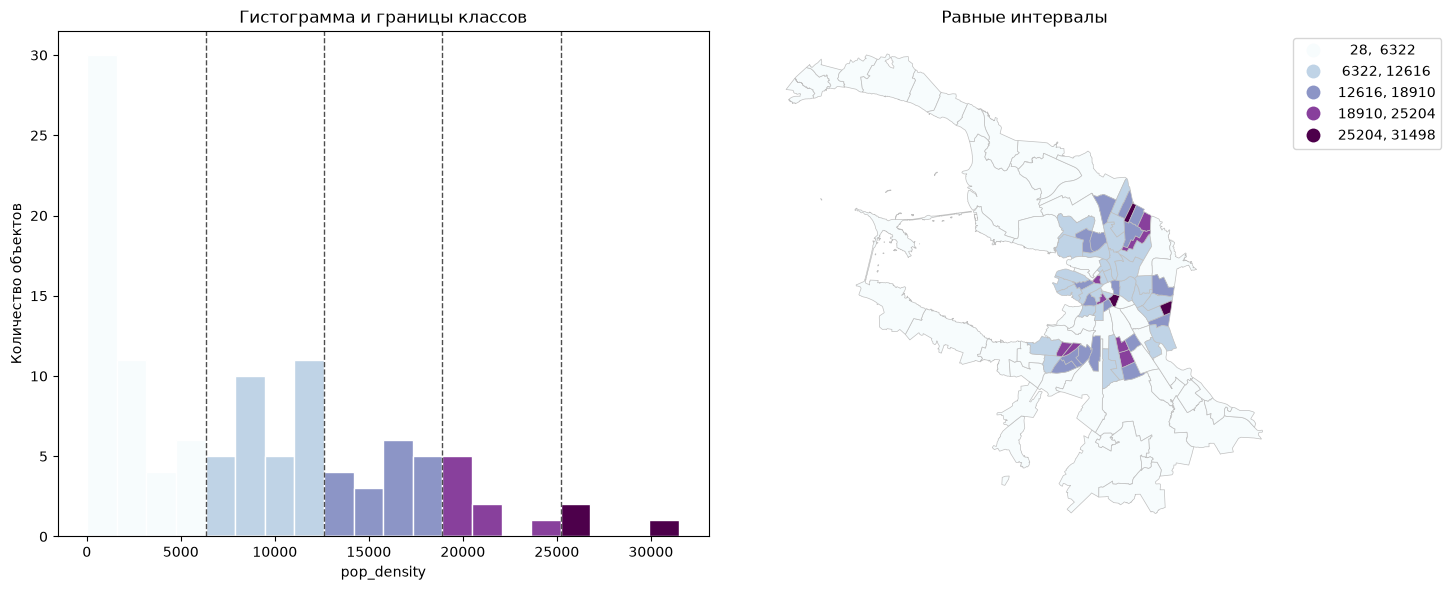

In [8]:
okrug_utm["equal_interval"] = equal_interval.yb

plot_classification(okrug_utm, "pop_density", equal_interval, "Равные интервалы")

Интервалы одинаковые, но большинство округов (82 из 111) попали в первые два класса, а в двух верхних классах — лишь единицы. При неравномерном распределении этот метод «прячет» различия между большинством объектов.


### 2.4. Квантили

Значения сортируют и делят на `k` классов с **одинаковым числом объектов**: при 111 округах и 5 классах в каждом около 22 округов.

- **Достоинства:** все цвета палитры используются одинаково, и карта получается контрастной. Классы легко интерпретировать как ранги: «20 % округов с самой высокой плотностью».
- **Недостатки:** метод учитывает только порядок значений, а не разницу между ними. Близкие значения могут оказаться в разных классах, а сильно различающиеся — в одном. Ширина интервалов при этом может очень сильно различаться.
- **Когда использовать:** важно сравнить положение объектов относительно друг друга или сравнить серию карт. В эксперименте [Brewer, Pickle, 2002] читатели лучше всего справлялись с картами, построенными методом квантилей.

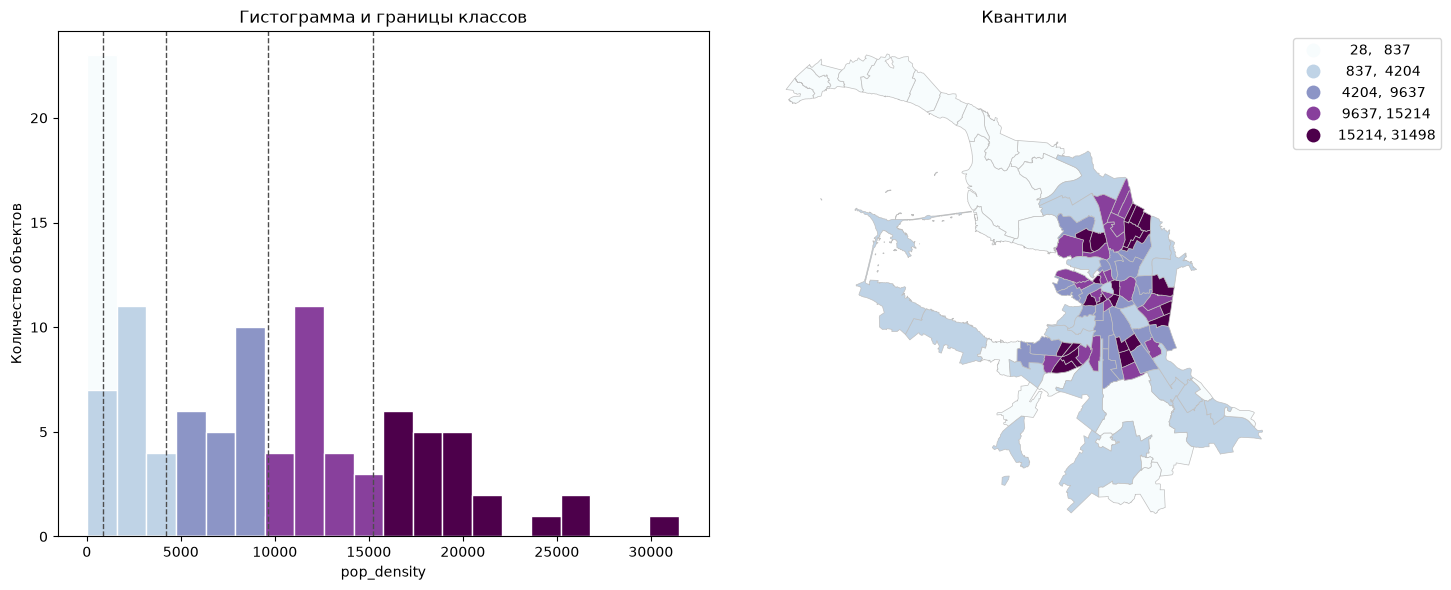

In [9]:
quantiles = mc.Quantiles(okrug_utm["pop_density"], k=k)
okrug_utm["quantiles"] = quantiles.yb

plot_classification(okrug_utm, "pop_density", quantiles, "Квантили")

Цвета на карте распределены равномерно, и карта выглядит контрастной. Но ширина интервалов сильно отличается: в один класс могут попасть очень разные значения, а близкие значения — в разные классы.


### 2.5. Естественные границы (оптимальный метод Дженкса)

Изначально «естественными» называли границы, которые картограф проводил вручную по провалам на гистограмме или графике распределения. Такой выбор субъективен, поэтому Дж. Дженкс предложил **оптимальный** метод [Jenks, Caspall, 1971]. Границы подбирают так, чтобы сумма квадратов отклонений значений от средних своих классов была минимальной. Иными словами, значения внутри класса как можно ближе друг к другу, а классы как можно сильнее отличаются между собой.

Качество классификации оценивают показателем **GVF** (_goodness of variance fit_). Он равен доле общей дисперсии, которая приходится на различия между классами, и принимает значения от 0 до 1. Чем ближе GVF к 1, тем лучше классы описывают данные.

- **Достоинства:** метод лучше остальных учитывает распределение данных.
- **Недостатки:** границы «некруглые», их сложно читать. Кроме того, границы зависят от конкретного набора данных, поэтому карты, построенные этим методом по разным данным, нельзя сравнивать.
- **Когда использовать:** распределение неравномерное, и важно, чтобы классы отражали группы близких значений.

<p style="color:#26528C; font-style:italic">В <strong>mapclassify</strong> есть два похожих классификатора. <code>FisherJenks</code> точно находит оптимальные границы по Дженксу. <code>NaturalBreaks</code> ищет их приближённо, похожим на k-средних алгоритмом со случайным начальным приближением, поэтому его результат может меняться от запуска к запуску. Мы используем точный вариант.</p>

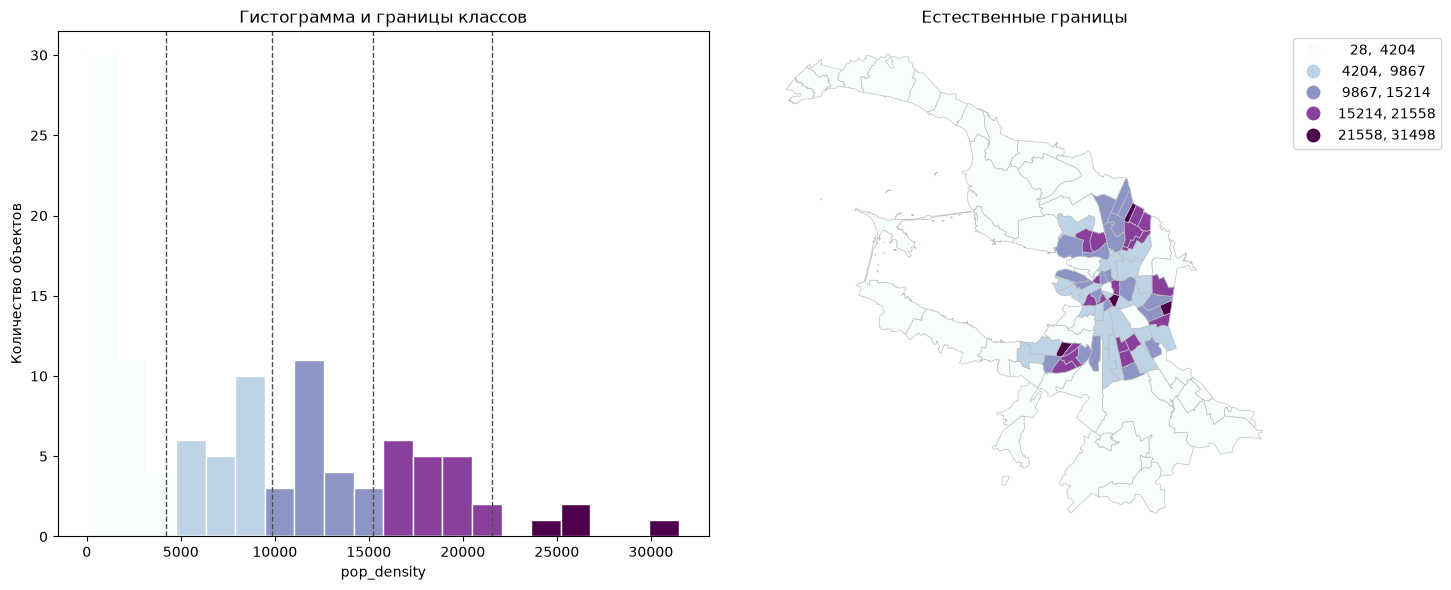

In [10]:
natural_breaks = mc.FisherJenks(okrug_utm["pop_density"], k=k)
okrug_utm["natural_breaks"] = natural_breaks.yb

plot_classification(okrug_utm, "pop_density", natural_breaks, "Естественные границы")

Классы получились разного размера: 45, 23, 21, 18 и 4 округа. Метод не стремится заполнить классы поровну, он объединяет близкие значения.

Посчитаем GVF для всех методов, которые мы уже рассмотрели:

In [11]:
def gvf(values, classifier):
    """Goodness of variance fit: доля дисперсии, объяснённая разбиением на классы."""
    sdam = ((values - values.mean()) ** 2).sum()
    sdcm = sum(
        ((values[classifier.yb == i] - values[classifier.yb == i].mean()) ** 2).sum()
        for i in range(len(classifier.bins))
    )
    return 1 - sdcm / sdam


for name, classifier in [("Равные интервалы", equal_interval),
                         ("Квантили", quantiles),
                         ("Естественные границы", natural_breaks)]:
    print(f"{name}: GVF = {gvf(okrug_utm['pop_density'], classifier):.3f}")

Равные интервалы: GVF = 0.938
Квантили: GVF = 0.928
Естественные границы: GVF = 0.959


У естественных границ GVF самый высокий: по определению это лучшее разбиение на заданное число классов. Однако высокий GVF не означает, что карту легче читать. Это лишь один из критериев.

### 2.6. Максимальные разрывы

Значения сортируют, вычисляют разности между соседними значениями и проводят границы классов по `k − 1` **наибольшим разрывам**.

- **Достоинства:** метод прост и учитывает разрывы в данных.
- **Недостатки:** метод смотрит только на отдельные разрывы и не учитывает, как значения распределены внутри классов. Выброс, далеко отстоящий от остальных значений, почти всегда получает отдельный класс.
- **Когда использовать:** в данных есть явные разрывы, и их нужно показать.

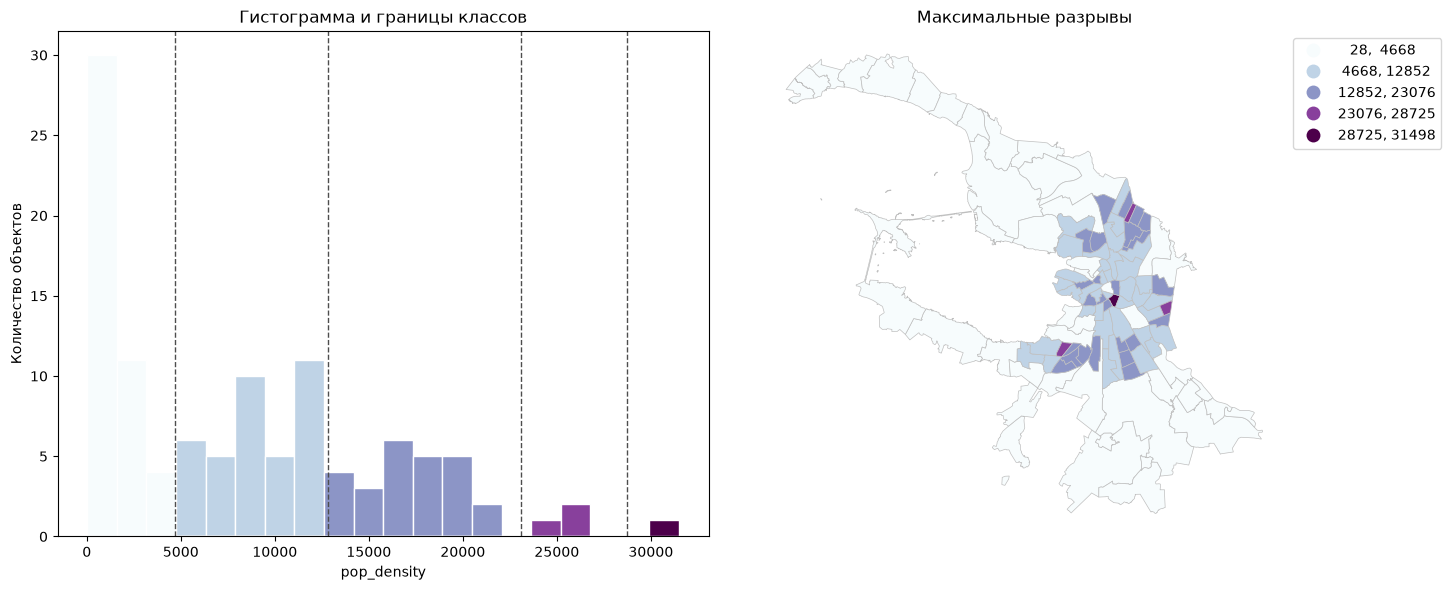

In [12]:
maximum_breaks = mc.MaximumBreaks(okrug_utm["pop_density"], k=k)
okrug_utm["maximum_breaks"] = maximum_breaks.yb

plot_classification(okrug_utm, "pop_density", maximum_breaks, "Максимальные разрывы")

Самые большие разрывы пришлись на верхнюю часть распределения, где значений мало. В итоге в два верхних класса попали лишь несколько округов, а остальные распределились по трём нижним.

### 2.7. Среднее и стандартное отклонение

Границы классов проводят на расстоянии одного, двух и более стандартных отклонений (σ) от среднего значения: $\bar{x} - 2\sigma$, $\bar{x} - \sigma$, $\bar{x} + \sigma$, $\bar{x} + 2\sigma$. Число классов задаётся не параметром `k`, а самими данными.

- **Достоинства:** каждый класс показывает, насколько значение выше или ниже среднего.
- **Недостатки:** метод корректно работает только для распределений, близких к нормальному. При асимметричном распределении часть границ может оказаться за пределами диапазона значений, а классы — пустыми. Кроме того, читателю нужно понимать, что такое стандартное отклонение.
- **Когда использовать:** важно сравнение со средним значением, а распределение близко к нормальному.

In [13]:
std_mean = mc.StdMean(okrug_utm["pop_density"])
okrug_utm["std_mean"] = std_mean.yb

print(f"Среднее: {okrug_utm['pop_density'].mean():.0f}")
print(f"Стандартное отклонение: {okrug_utm['pop_density'].std():.0f}")

std_mean

Среднее: 8393
Стандартное отклонение: 7398


StdMean

      Interval         Count
----------------------------
(    -inf, -6402.38] |     0
(-6402.38,   995.49] |    23
(  995.49, 15791.21] |    66
(15791.21, 23189.08] |    18
(23189.08, 31498.29] |     4

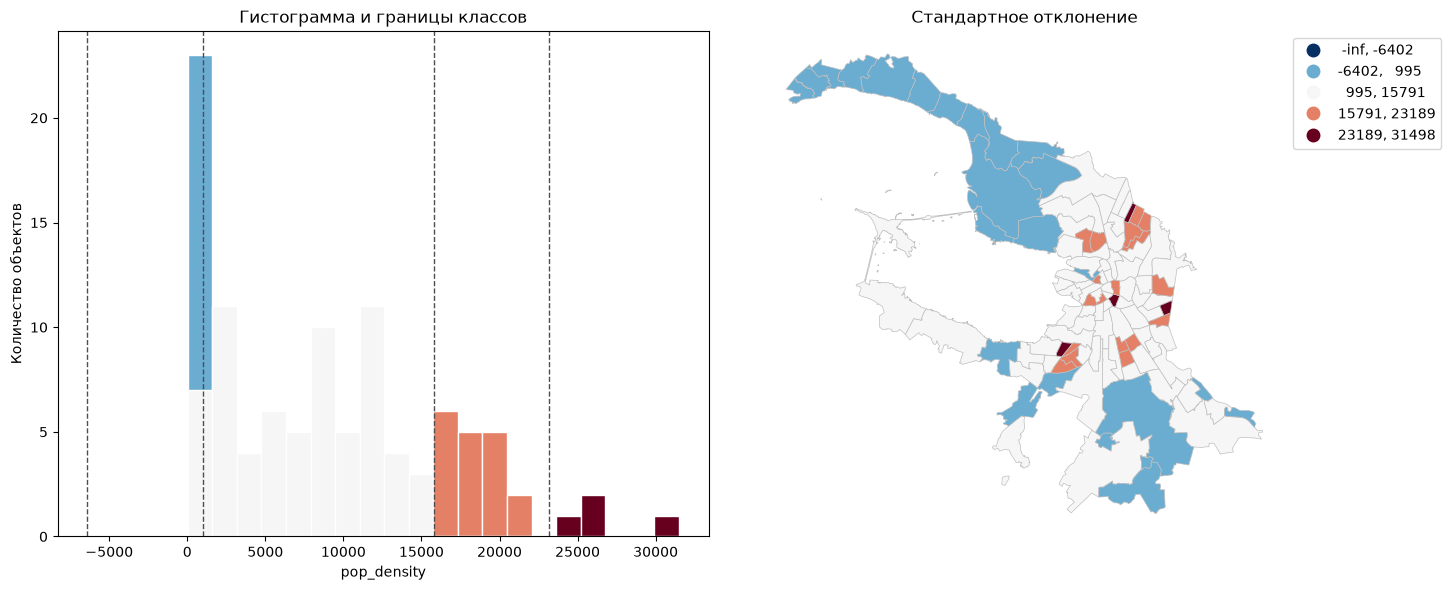

In [14]:
plot_classification(okrug_utm, "pop_density", std_mean, "Стандартное отклонение", cmap="RdBu_r")

Обратите внимание: здесь мы использовали **расходящуюся** палитру `RdBu_r` (см. раздел 1.2). Классы откладываются в обе стороны от среднего, поэтому важно визуально отделить значения ниже среднего от значений выше среднего.

Распределение плотности асимметричное, поэтому граница $\bar{x} - 2\sigma$ оказалась отрицательной, а первый класс пустым: плотность населения не может быть меньше нуля. Это пример того, что метод плохо подходит для таких данных.

### 2.8. Пользовательские интервалы

Границы классов можно задать самостоятельно. Обычно их выбирают на основе одного из статистических методов, округляя границы до «круглых» значений, которые легко читать и сравнивать.

Посмотрим на границы, полученные методом естественных границ:


In [15]:
natural_breaks.bins

array([ 4203.65398166,  9866.92713541, 15214.46609137, 21558.12875045,
       31498.29459848])

Зададим близкие к ним, но округлённые границы (последняя граница должна быть не меньше максимального значения):


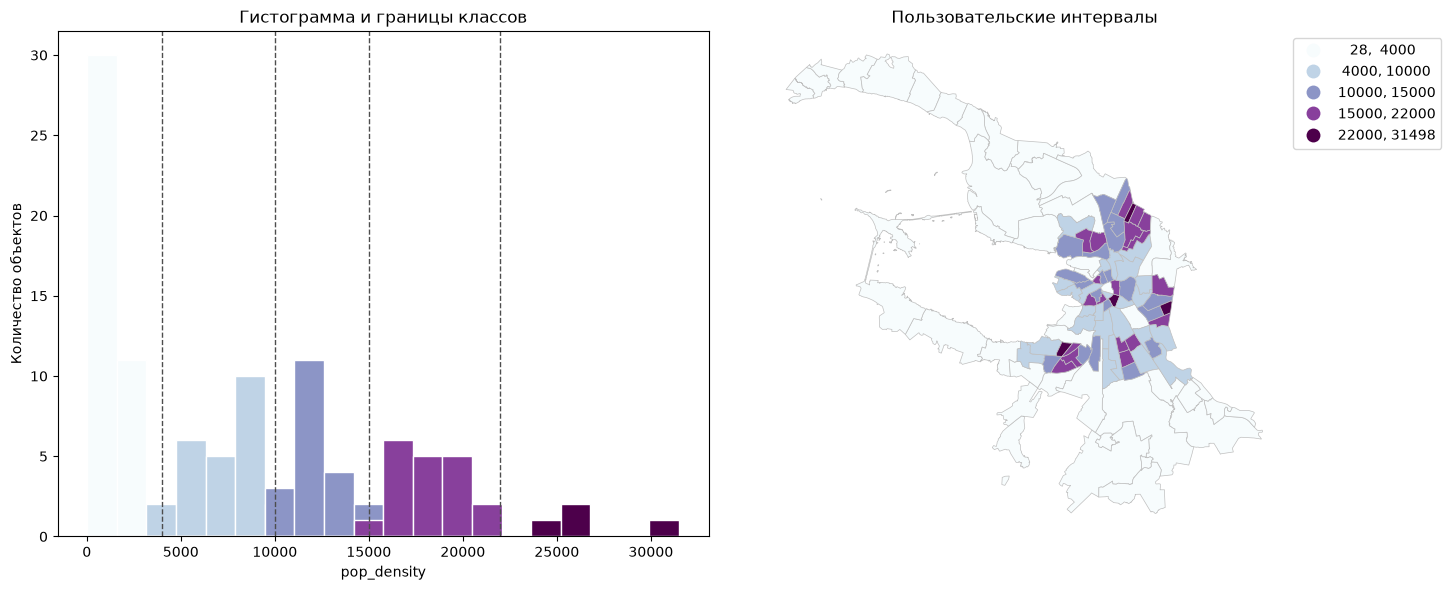

In [16]:
bins = [4000, 10000, 15000, 22000, okrug_utm["pop_density"].max()]

user_defined = mc.UserDefined(okrug_utm["pop_density"], bins)
okrug_utm["user_defined"] = user_defined.yb

plot_classification(okrug_utm, "pop_density", user_defined, "Пользовательские интервалы")

## 3. Сравнение методов классификации

Посмотрим, в какие классы попадают одни и те же округа при разных методах классификации. Отсортируем округа по плотности населения и для каждого метода покажем цветом номер класса:


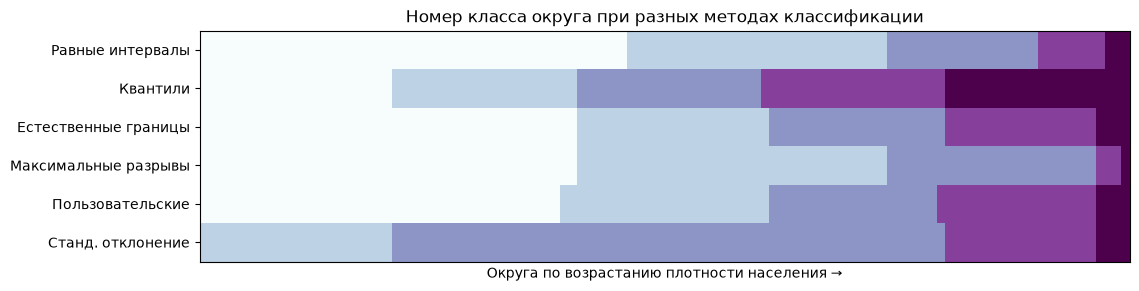

In [17]:
schemes = {
    "equal_interval": "Равные интервалы",
    "quantiles": "Квантили",
    "natural_breaks": "Естественные границы",
    "maximum_breaks": "Максимальные разрывы",
    "user_defined": "Пользовательские",
    "std_mean": "Станд. отклонение",
}

classes = okrug_utm.sort_values("pop_density")[list(schemes)]

fig, ax = plt.subplots(figsize=(12, 3))

ax.imshow(classes.T.values, aspect="auto", cmap="BuPu", interpolation="none")

ax.set_yticks(range(len(schemes)))
ax.set_yticklabels(schemes.values())
ax.set_xticks([])
ax.set_xlabel("Округа по возрастанию плотности населения →")
ax.set_title("Номер класса округа при разных методах классификации")

plt.show()

Одни и те же округа при разных методах попадают в разные классы. При равных интервалах большинство округов оказываются в первых классах, а при квантилях они равномерно распределены по всем классам.


## Итог

В этом разделе мы разобрали, как строить картограммы.

Картограмма показывает среднюю интенсивность явления в пределах территориальных единиц, поэтому её строят по относительным показателям: плотностям, долям, значениям на число жителей. Палитру выбирают по типу данных: последовательную для количественных значений, расходящуюся для значений с осмысленным центром, качественную для категорий.

Перед классификацией нужно посмотреть на распределение показателя. Метод равных интервалов подходит для равномерно распределённых данных, но при сильной асимметрии почти все объекты попадают в первые классы. Квантили равномерно распределяют объекты по классам и делают карту контрастной, но могут разнести близкие значения по разным классам. Естественные границы (оптимальный метод Дженкса) делают значения внутри классов максимально близкими и хорошо работают с неравномерным распределением, хотя их границы получаются «некруглыми». Максимальные разрывы проводят границы по самым большим скачкам в данных, но часто выделяют в отдельный класс единичные выбросы. Метод стандартного отклонения показывает, насколько значения отличаются от среднего. Пользовательские интервалы позволяют задать «круглые» границы, удобные для чтения и для сравнения нескольких карт.

Одни и те же данные при разных методах дают заметно разные карты, поэтому выбор метода классификации нужно обосновывать, а не оставлять на значение по умолчанию.


**Литература:**

- Slocum T. A., McMaster R. B., Kessler F. C., Howard H. H. Thematic Cartography and Geovisualization. 4th ed. Boca Raton: CRC Press, 2022.
- Jenks G. F., Caspall F. C. Error on choroplethic maps: definition, measurement, reduction // Annals of the Association of American Geographers. 1971. Vol. 61, № 2. P. 217–244.
- Brewer C. A., Pickle L. Evaluation of methods for classifying epidemiological data on choropleth maps in series // Annals of the Association of American Geographers. 2002. Vol. 92, № 4. P. 662–681.